# Computer Vision HS2026 – Lab 01 Assignment: Local Features

ETH Zurich, Computer Science Department

## Objective

In this lab assignment, you will implement your own feature detector and a basic matching protocol to
establish pixel-wise correspondences between images. Along with this notebook, some test images are
provided in `images/`.

The main structure of the program is provided. You write your code directly in this notebook, in the
functions marked with `TODO`. The cells in between run your functions on the test images and show the
results.

**Do not modify the function interfaces.** Do not change the already implemented functions in `helpers/`
(visualization and descriptor extraction). You will need the following Python packages: `numpy`,
`opencv-python`, `scipy`, `matplotlib` and `ipympl`.

## Hand-in

Hand in a **zip file of the complete exercise folder** via Moodle. It must contain:

- `lab01-local-features.ipynb`: this notebook with your code, **all outputs** (run all cells before saving) and your answers,
- `helpers/`: the provided helper functions (unchanged),
- `images/`: the provided images.

**Do not include your virtual environment** (e.g. `cv_env/`) in the zip.

<p style="color:red; font-size:2em; font-weight:bold; margin:0.6em 0">Deadline: Friday, October 9, 2026, 23:59</p>

## Setup

1. Download the template from Moodle and extract it to a working directory.
2. Create a virtual environment (recommended):
   ```bash
   # On Windows
   python -m venv cv_env
   cv_env\Scripts\activate

   # On macOS/Linux
   python3 -m venv cv_env
   source cv_env/bin/activate
   ```
3. Install the required packages:
   ```bash
   pip install numpy scipy opencv-python matplotlib jupyterlab ipympl
   ```
4. Open this notebook (`jupyter lab lab01-local-features.ipynb`, or open it in VS Code and select
   `cv_env` as kernel) and run the cells from top to bottom.

On the first run, this will raise a `NotImplementedError` – this is expected and shows you where to
add your code.

## Grading

| Part | Points |
|---|---|
| Code: 1.1, 1.2, 1.4, 1.5 (Harris detector) | 30 |
| Code: 2.1 – 2.3 (description and matching) | 30 |
| 1.3 What does $M$ tell us? All six pixel types found (all or nothing) | 10 |
| 1.6 Questions 1.6.1 – 1.6.5 (detector invariance) | 15 |
| 2.4 Questions 2.4.1 – 2.4.5 (matching invariance) | 15 |
| **Total** | **100** |

Answer each question in the cell **✏️ Your answer** below it (2–3 sentences). Refer to what you see in the figures.

**Coordinate convention**

- Images: `img[row, col]` or `img[y, x]`
- Keypoints: stored as `[x, y]` where x = col, y = row
- Gradients: `Ix` = horizontal (along x / columns), `Iy` = vertical (along y / rows)

**Avoid Python for-loops over pixels or descriptors**: use vectorized numpy operations.

In [1]:
%matplotlib inline

import cv2
import numpy as np
from scipy import ndimage  # for scipy.ndimage.maximum_filter
from scipy import signal  # for scipy.signal.convolve2d

from helpers import extract_patches, show_keypoints, show_keypoints_pair, show_matches

# constants
HARRIS_SIGMA = 1.0
HARRIS_K = 0.05  # in the range of 0.04 - 0.06
HARRIS_THRESH = 1e-5
MATCHING_RATIO_TEST_THRESHOLD = 0.5

## 1 Detection (55 pts)

In this section, you will implement a Harris corner detector to find interest points in an image. For
this, you will start by computing the Harris response function $C$ for all pixels in an image.
Afterwards, a pixel $(i, j)$ is selected as a keypoint if the following two conditions are satisfied:
$C(i, j)$ is above a certain detection threshold $T$ and $C(i, j)$ is a local maximum in its
$3 \times 3$ neighborhood. For more details, please refer to [1].

### 1.1 Image gradients (5 pts)

Compute the image gradients $I_x$ and $I_y$ in the $x$ and $y$ directions respectively. You may use the
`scipy.signal.convolve2d` function with the right convolutional filters.

$$I_x(i, j) = \frac{I(i, j + 1) - I(i, j - 1)}{2}, \qquad I_y(i, j) = \frac{I(i + 1, j) - I(i - 1, j)}{2}$$

In [2]:
def image_gradients(img: np.ndarray):
    '''Compute the image gradients Ix and Iy.

    Args:
        img (np.ndarray): Gray-scale float image of shape (H, W).

    Returns:
        Ix, Iy (np.ndarray): Gradients along x (columns) and y (rows), both of shape (H, W).
    '''

    Ix = signal.convolve2d(img, 0.5 * np.array([[1, 0, -1]]), mode='same')
    Iy = signal.convolve2d(img, 0.5 * np.array([[1], [0], [-1]]), mode='same')
    
    return Ix, Iy

### 1.2 Local auto-correlation matrix (10 pts)

Compute the elements of the local auto-correlation matrix defined by the following equation at each
pixel position $p$:

$$M_p = \sum_{p' \in \mathcal{N}(p)} w_{p'} \begin{bmatrix} I_x(p')^2 & I_x(p') I_y(p') \\ I_y(p') I_x(p') & I_y(p')^2 \end{bmatrix},$$

where $\mathcal{N}(p)$ is a neighbourhood of point $p$. The local weighting $w$ is generally chosen to be
Gaussian with standard deviation $\sigma$ (centered in $(0, 0)$). You may use the `cv2.GaussianBlur`
function.

In [3]:
def auto_correlation_matrix(Ix: np.ndarray, Iy: np.ndarray, sigma: float):
    '''Compute the three distinct elements of the local auto-correlation matrix M at every pixel.

    Args:
        Ix, Iy (np.ndarray): Image gradients of shape (H, W).
        sigma (float): Standard deviation of the Gaussian weighting.

    Returns:
        Mxx, Mxy, Myy (np.ndarray): Weighted sums of Ix^2, Ix*Iy and Iy^2, each of shape (H, W).
    '''
    # TODO: compute the auto-correlation matrix here
    # You may refer to cv2.GaussianBlur or scipy.signal.convolve2d to perform the weighted sum

    Mxx = cv2.GaussianBlur(Ix * Ix, (0, 0), sigma)
    Mxy = cv2.GaussianBlur(Ix * Iy, (0, 0), sigma)
    Myy = cv2.GaussianBlur(Iy * Iy, (0, 0), sigma)

    return Mxx, Mxy, Myy

### 1.3 What does $M$ tell us? (interactive, 10 pts)

$M$ comes from approximating the shift error $E(u, v) = \sum_{\mathcal{N}(p)} w \,[I(x+u, y+v) - I(x, y)]^2$ by the quadratic form
$[u\ v]\, M\, [u\ v]^\top$. The cell below uses **your** `image_gradients` and `auto_correlation_matrix`.

**Move the mouse** over the house: the zoomed patch shows the two eigenvectors of $M$ at that pixel (length $\propto \sqrt{\lambda}$,
$\lambda_1$ red, $\lambda_2$ blue, the yellow circle is the window). **Click** a pixel to see the true shift error (surface) together with
its quadratic approximation (red grid). Hunt for the six kinds of pixels in the checklist; a click on a matching pixel ticks it off.

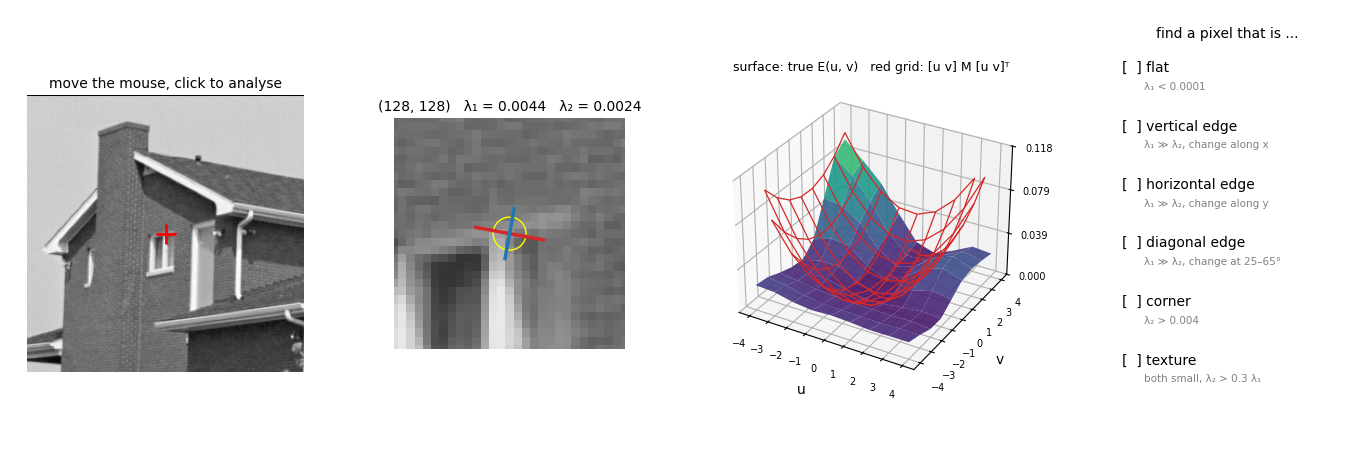

In [4]:
%matplotlib widget
from helpers.explore import PatchExplorer

house = cv2.imread("images/house.jpg", cv2.IMREAD_GRAYSCALE)
explorer = PatchExplorer(house, image_gradients, auto_correlation_matrix, HARRIS_SIGMA)
explorer.hunt()

**Task (10 pts, all or nothing):** find one pixel of each of the six types. `explorer.show_answers` below checks your pixels
(✔ / ✘ in the figure titles) and prints how many are correct.

While hunting, look at the surfaces and think about (not graded):

- **Edges:** what do the eigenvectors and the surface look like? Why is the red grid a valley although the true error is one-sided?
- **Corner vs. texture:** how do the eigenvalues of the brick wall compare with those of a real corner? What does that mean for the threshold $T$?
- **Approximation:** where is the red grid a poor approximation of the surface even for small shifts, and why?

Enter the pixels you found below, so that the figures are stored in your notebook (the interactive figure above is not saved;
`explorer.found` holds what the hunt ticked off).

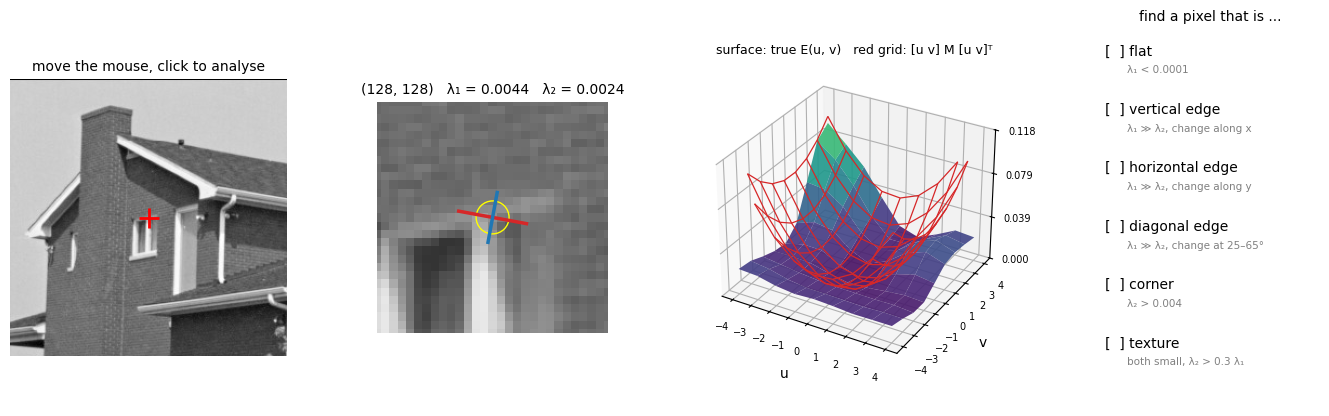

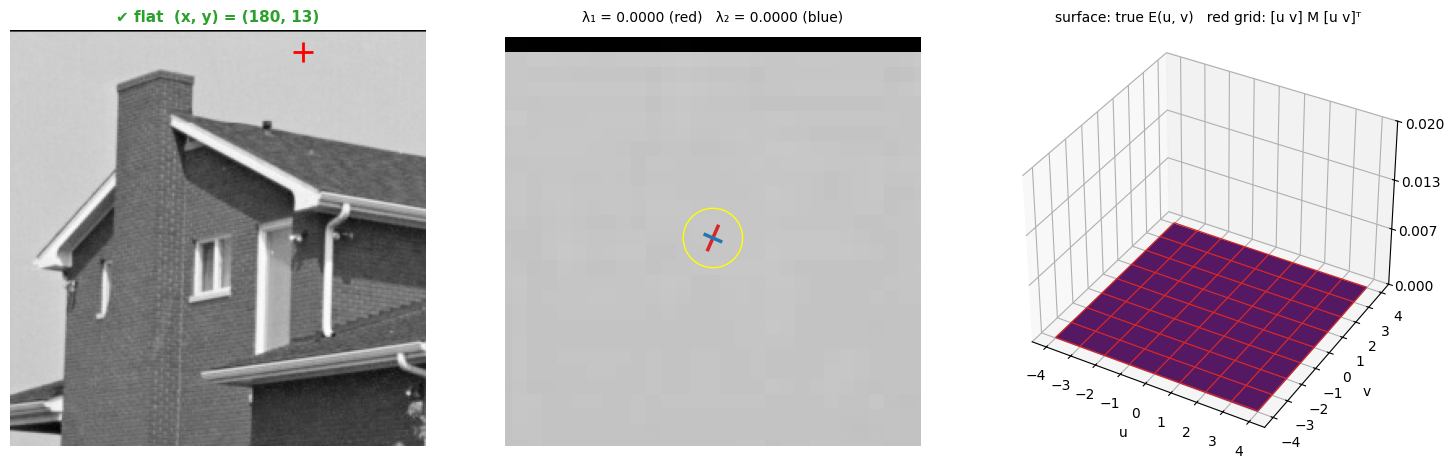

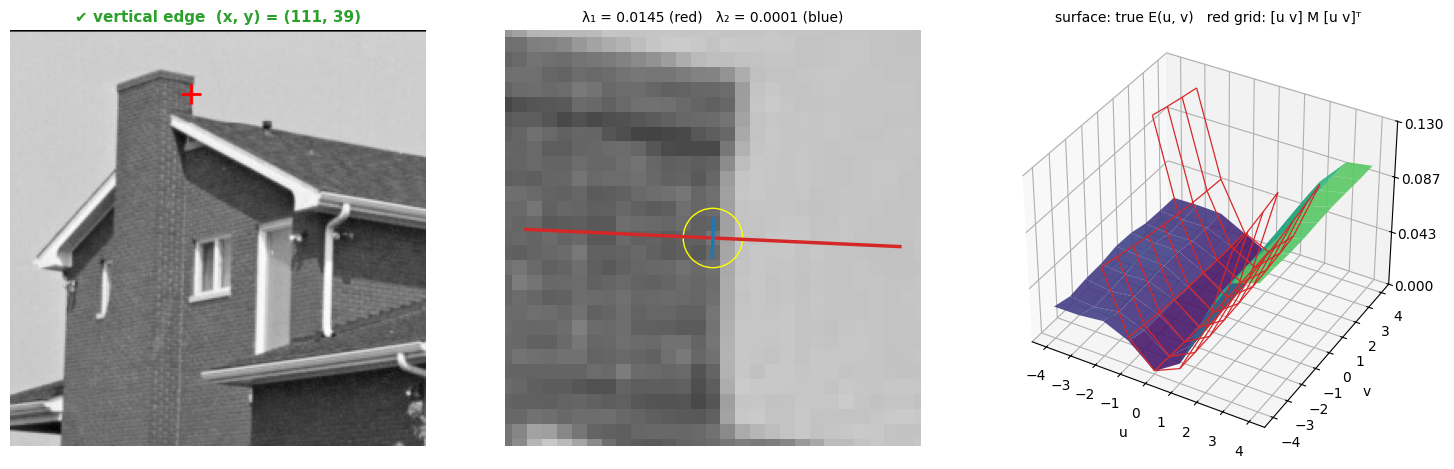

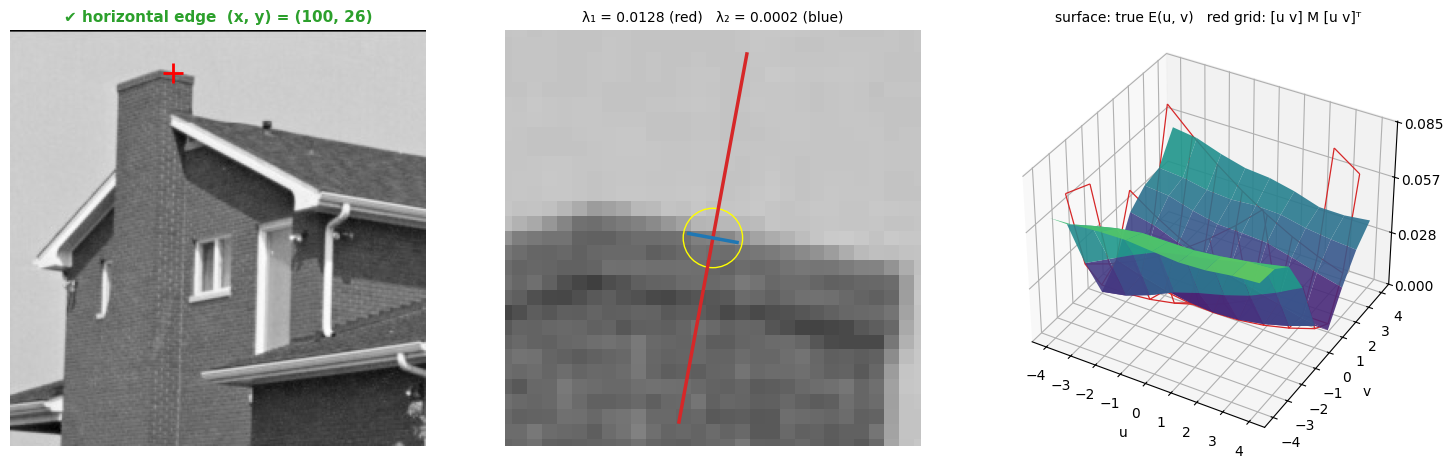

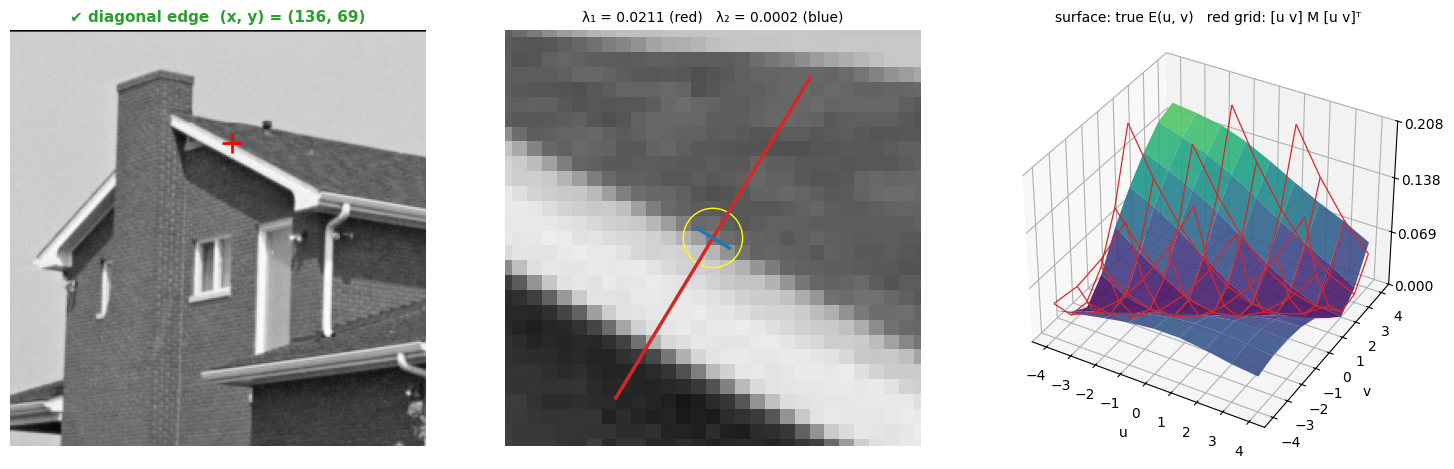

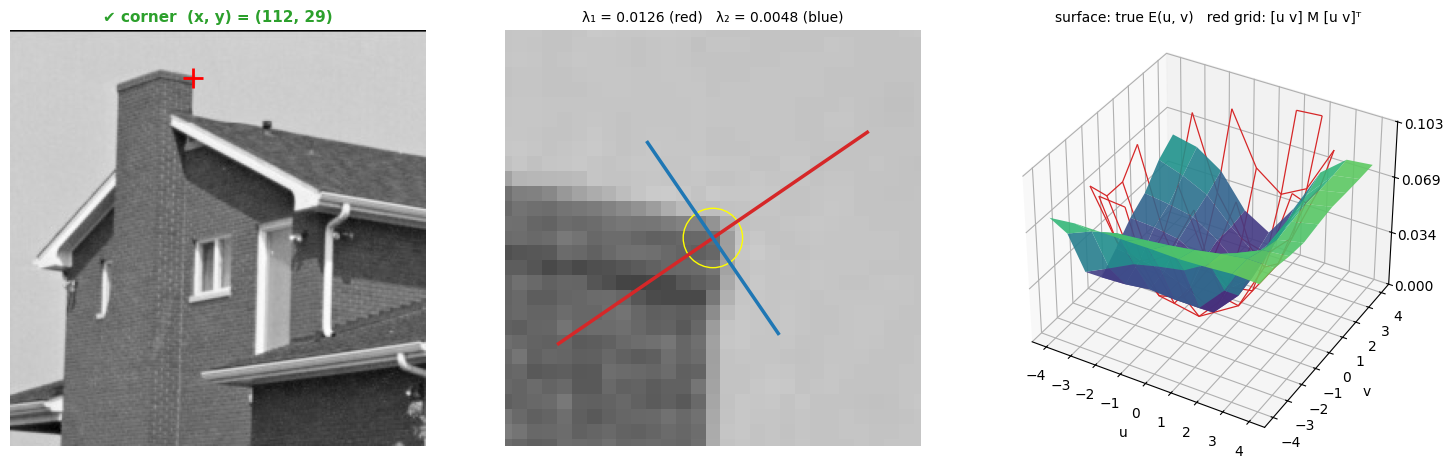

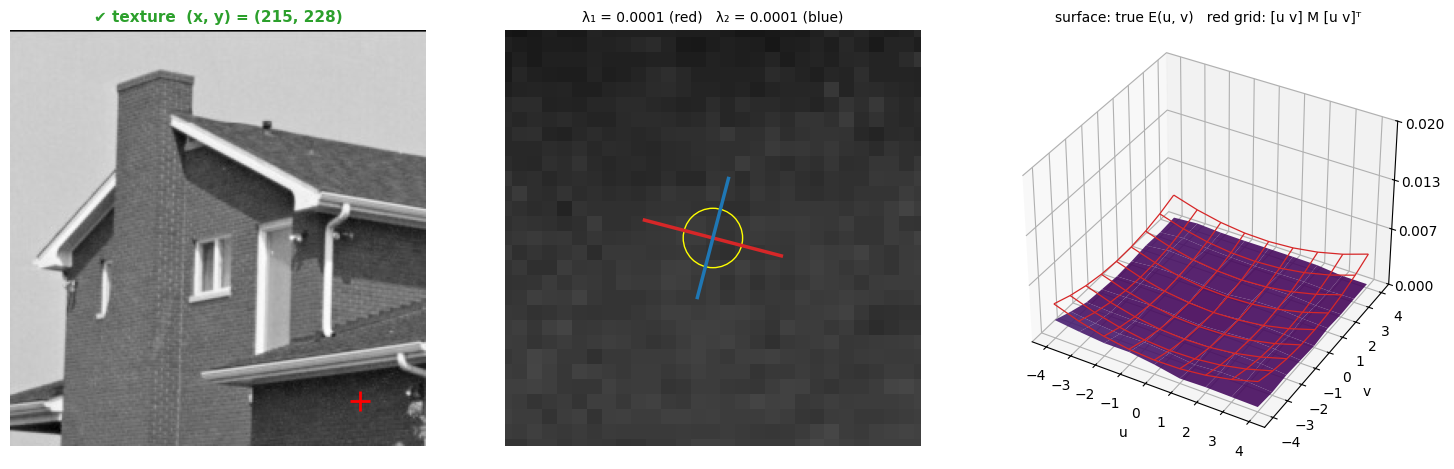

6 / 6 pixel types found correctly


In [5]:
%matplotlib inline

# TODO: replace (x, y) with the pixels you found (explorer.found holds what the hunt ticked off)
FOUND = {
    "flat": (180, 13),
    "vertical edge": (111, 39),
    "horizontal edge": (100, 26),
    "diagonal edge": (136, 69),
    "corner": (112, 29),
    "texture": (215, 228),
}
explorer.show_answers(FOUND)

### 1.4 Harris response function (5 pts)

The Harris response function can be defined as $C(i, j) = \det(M_{i,j}) - k \, \mathrm{Tr}^2(M_{i,j})$ with
$k \in [0.04, 0.06]$, an empirically determined constant. Compute the Harris response function for all
pixels using the closed-form formulas for the determinant and trace.

In [6]:
def harris_response(Mxx: np.ndarray, Mxy: np.ndarray, Myy: np.ndarray, k: float) -> np.ndarray:
    '''Compute the Harris response C = det(M) - k * Tr(M)^2 at every pixel.

    Returns:
        np.ndarray: Harris response C of shape (H, W).
    '''
    # TODO: compute the Harris response function C here

    det_M = Mxx * Myy - Mxy * Mxy
    trace_M = Mxx + Myy
    C = det_M - k * (trace_M ** 2)

    return C

### 1.5 Detection criteria (10 pts)

Take into account the two detection conditions (strength and local maximality of the response)
mentioned at the beginning of Section 1 to obtain the final keypoints. For the local maximum check, you
may take advantage of the `scipy.ndimage.maximum_filter` function.

In [7]:
def detect_keypoints(C: np.ndarray, thresh: float) -> np.ndarray:
    '''Detection with threshold and non-maximum suppression.

    Args:
        C (np.ndarray): Harris response of shape (H, W).
        thresh (float): Threshold for corner strength.

    Returns:
        np.ndarray: Detected corners [x, y] of shape (q, 2).
    '''

    # TODO: detection and find the corners here
    # For the non-maximum suppression, you may refer to scipy.ndimage.maximum_filter to check a 3x3 neighborhood.
    # You may refer to np.where to find coordinates of points that fulfill some condition;
    # Please, pay attention to the order of the coordinates.
    # You may refer to np.stack to stack the coordinates to the correct output format

    local_max = ndimage.maximum_filter(C, size=3)
    ys, xs = np.where((C > thresh) & (C == local_max))
    corners = np.stack((xs, ys), axis=-1)

    return corners

The following function chains the four steps. It is provided, as is the code that runs the detector on
the two test images `blocks.jpg` and `house.jpg`.

In [8]:
def extract_harris(img: np.ndarray, sigma: float = 1.0, k: float = 0.05, thresh: float = 1e-5):
    '''Extract Harris corners from a gray-scale uint8 image of shape (H, W).

    Args:
        sigma (float): Gaussian kernel standard deviation. Suggested range [0.5, 2.0].
        k (float): Harris detector free parameter. Suggested range [0.04, 0.06].
        thresh (float): Threshold for corner strength. Suggested range [1e-6, 1e-4].

    Returns:
        Detected corners [x, y] of shape (q, 2) and the Harris response C of shape (H, W).
    '''
    img = img.astype(float) / 255.0
    Ix, Iy = image_gradients(img)
    Mxx, Mxy, Myy = auto_correlation_matrix(Ix, Iy, sigma)
    C = harris_response(Mxx, Mxy, Myy, k)
    corners = detect_keypoints(C, thresh)
    return corners, C

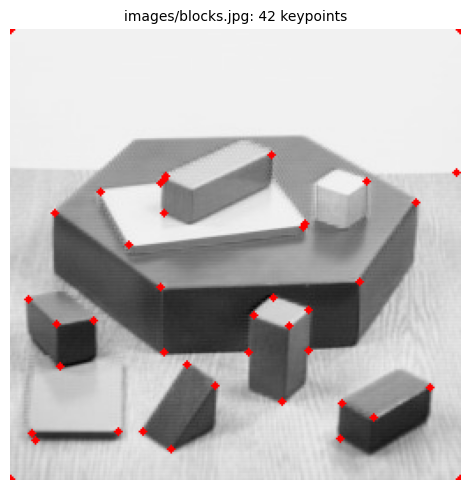

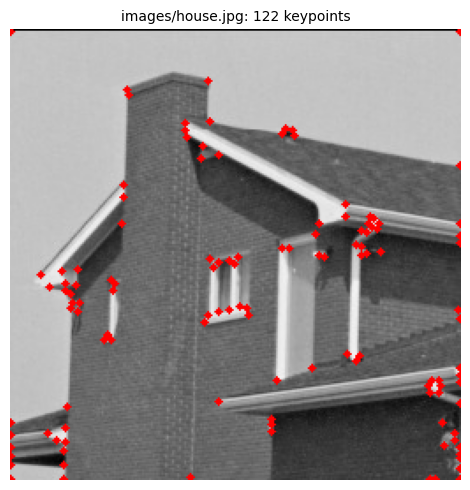

In [9]:
for name in ["images/blocks.jpg", "images/house.jpg"]:
    img = cv2.imread(name, cv2.IMREAD_GRAYSCALE)
    corners, C = extract_harris(img, HARRIS_SIGMA, HARRIS_K, HARRIS_THRESH)
    show_keypoints(img, corners, name)

### 1.6 What is the Harris detector invariant to? (interactive, 15 pts)

**Task.** We change the house image in a controlled way and run **your** detector with the **same parameters** ($\sigma$, $k$, $T$)
on the changed image. Because we know the transformation, every original keypoint can be mapped to where it should appear in the
changed image. A keypoint is *re-detected* if your detector finds a keypoint within 2 pixels of that position. The share of re-detected
keypoints is the **repeatability**: 1.0 means the detector is invariant to the change, 0 means nothing is found again.

In the figure: original keypoints on the left; on the right the mapped keypoints, green = re-detected, red = lost, and cyan circles for
everything the detector finds in the changed image. Keypoints within 8 pixels of the image border are shown in grey and not counted
(they may leave the image, and the border itself creates artificial responses).

**The sliders**

- `rotation [°]`: rotate the image about its centre.
- `image resize`: resize the whole image by this factor (2 = every structure twice as large, 0.5 = half).
- `I + c`: add a constant to all intensities (brighter / darker), clipped to $[0, 255]$.
- `a · I`: multiply all intensities by a constant (more / less contrast), clipped to $[0, 255]$.
- `threshold`: **absolute** keeps every pixel with $C > T$ as before. **top-K** ignores $T$ and keeps the $K$ pixels with the largest
  response, where $K$ is the number of keypoints found in the original image.

In [10]:
%matplotlib widget
from helpers.invariance import InvarianceExplorer

invariance = InvarianceExplorer(house, extract_harris, HARRIS_SIGMA, HARRIS_K, HARRIS_THRESH)
invariance.interact()

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='rotation [°]', layout=Layou…

The summary runs five fixed changes in both threshold modes. Under each column you see how many keypoints the absolute threshold finds in the
changed image (the original has 121): top-K can only make a difference where that number is *smaller* than in the original. Explain each column below (2–3 sentences each). Argue with the
gradients, the matrix $M$, its eigenvalues and the response $C$.

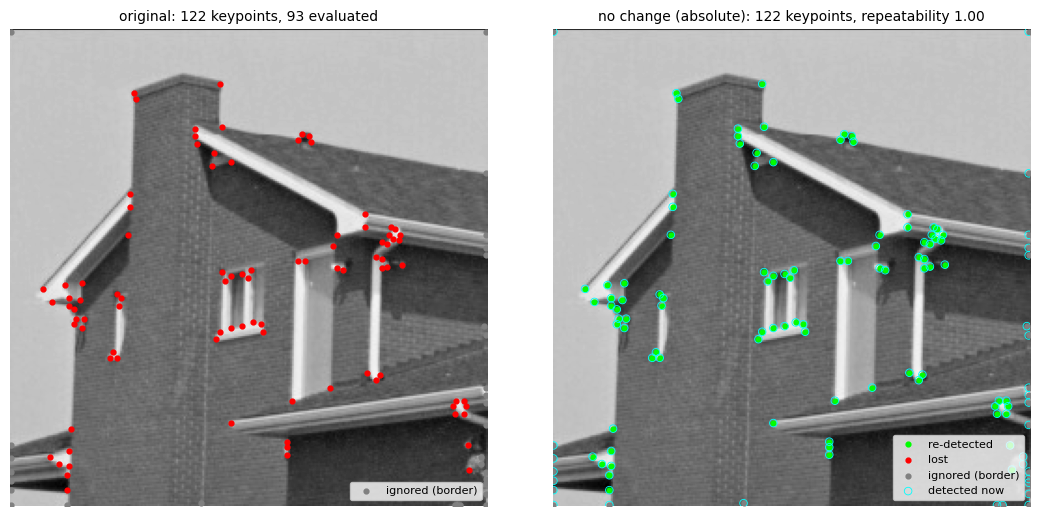

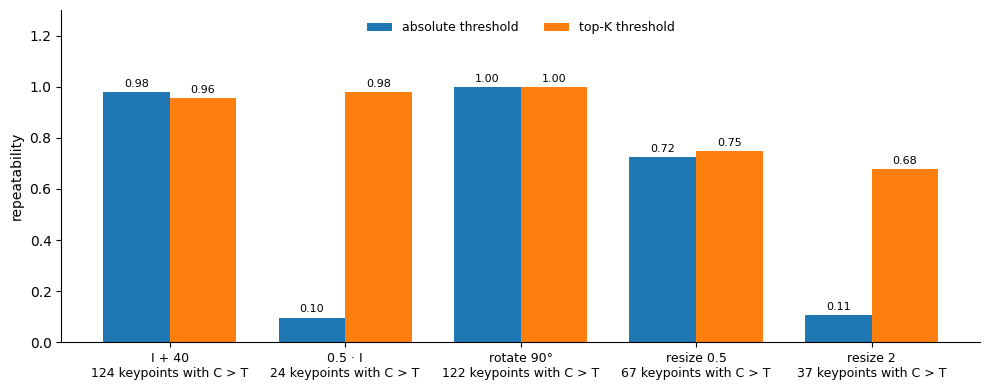

In [11]:
%matplotlib inline
invariance.summary()

#### 1.6.1 I + 40 (3 pts)

What is the impact on the repeatability, and why? Why is it not exactly 1?

✏️ Because the intensity of all pixels increases uniformly by a constant ($I+c$), the gradients remain unchanged, regardless of the choice of $c$. This means that $M$ is also identical and all detections are invariant. However, this may not always be the case. If $c$ is too large, some of the pixel intensities might get clipped at 255, which will shorten the gradient across some regions. This explains why repeatability isn't perfectly 1.

#### 1.6.2 0.5 · I (3 pts)

What is the impact on the repeatability with the absolute threshold and with top-K, and why?

✏️ Unlike the additive case, when scaling the pixel intensity by a constant ($I \cdot a$), the gradients are also scaled. Given that $M$ is constructed by the product of gradients, its entries are scaled quadratically $M' = a^2 M$. Furthermore, we know that the Harris Response is also quadratic in the entries of $M$, thus we have $C' = a^4 C$. For $a = 0.5$, we have that $C' = 1/16 C$. This means that a keypoint only survives if its original response was 16 times above the threshold. On the other hand, top-K does not suffer from this problem, since it ranks the highest K responses and the transformation affects all pixels uniformly.

#### 1.6.3 rotate 90° (3 pts)

What is the impact on the repeatability, and why?

✏️ There was no impact to repeatability because the rotation was by exactly 90 degrees. The Harris Response does not differentiate between gradients in x or y, thus they can be interchanged. This means that computing the determinant and trace of $M$ remains unchanged. 

Furthermore, the detector was invariant to rotation because a 90 degree rotation is isomorphic in the pixel representation of images. This means that the structure of the original image was preserved by just mapping its pixel coordinates. However, if the rotation hadn't been exactly by 90 degrees, the algorithm would've had to interpolate between pixels in the original image to fit them in the transformed pixel grid.

#### 1.6.4 resize 0.5 (3 pts)

What is the impact on the repeatability with the absolute threshold and with top-K, and why? Compare with the number of keypoints under the column.

✏️ Once again, downscaling an image is not an isomorphism. When scaling an image (by a factor < 1), we have to interpolate between pixels in the original image to fit them in the smaller grid representation. This means that we lose resolution and some of the image structure is lost. 

We observe absolute threshold picked up 67 keypoints with 0.72 repeatability, while top-K achieved 122 keypoints but it only pushed repeatability to 0.75. This indicates that keypoints were likely lost due to downscaled resolution and were mapped to unseen keypoints in the transformed image.

#### 1.6.5 resize 2 (3 pts)

What is the impact on the repeatability with the absolute threshold and with top-K, and why? Why does top-K not recover all keypoints?

✏️ In this case, upscaling an image is not always an isomorphism. When scaling an image (by a factor > 1), we effectively spread the intensity of an image over a bigger region, which means the gradients are now weaker between adjacent pixels in the transformed image. In this case, scaling the image by a factor of $a = 2$ means the gradients approximately halved, which results in a Harris Response $C' = 1/16 C$. This explains why absolute threshold only picked up 37 keypoints with repeatability 0.11.

Top-K fixes this by taking the strongest responses, picking up repeatability to 0.68.

However, it is unable to achieve perfect repeatability because the Harris Detector weights the $M$ matrix at a neighborhood $\mathcal{N}(p)$ around every pixel with $\sigma = 1$, which remained constant. When upscaling an image, structures are now captured in a bigger pixel grid, which are likely not sampled for weighting $M$.

## 2 Description & Matching (45 pts)

In this section, you will implement a matching protocol for image patches and test it out on the
provided image pair (`I1.jpg`, `I2.jpg`).

### 2.1 Local descriptors (5 pts)

We use the provided `extract_patches` function to extract $9 \times 9$ patches around the detected
keypoints, which will be used as descriptors. Make sure to first filter out the keypoints that are too
close to the image boundaries so as to avoid out-of-bounds issues.

In [12]:
def filter_keypoints(img: np.ndarray, keypoints: np.ndarray, patch_size: int = 9) -> np.ndarray:
    '''Filter keypoints that are too close to the image edges.

    Args:
        img (np.ndarray): Gray-scale image of shape (H, W).
        keypoints (np.ndarray): Keypoint locations [x, y] of shape (q, 2).
        patch_size (int, optional): Size of the patch to extract. Defaults to 9.

    Returns:
        np.ndarray: Filtered keypoint locations of shape (q', 2).
    '''
    # TODO: Filter out keypoints that are too close to the edges
    
    height, width = img.shape
    half_patch = patch_size // 2

    valid_indices = (
        (keypoints[:, 0] >= half_patch) &
        (keypoints[:, 0] < width - half_patch) &
        (keypoints[:, 1] >= half_patch) &
        (keypoints[:, 1] < height - half_patch)
    )

    return keypoints[valid_indices]

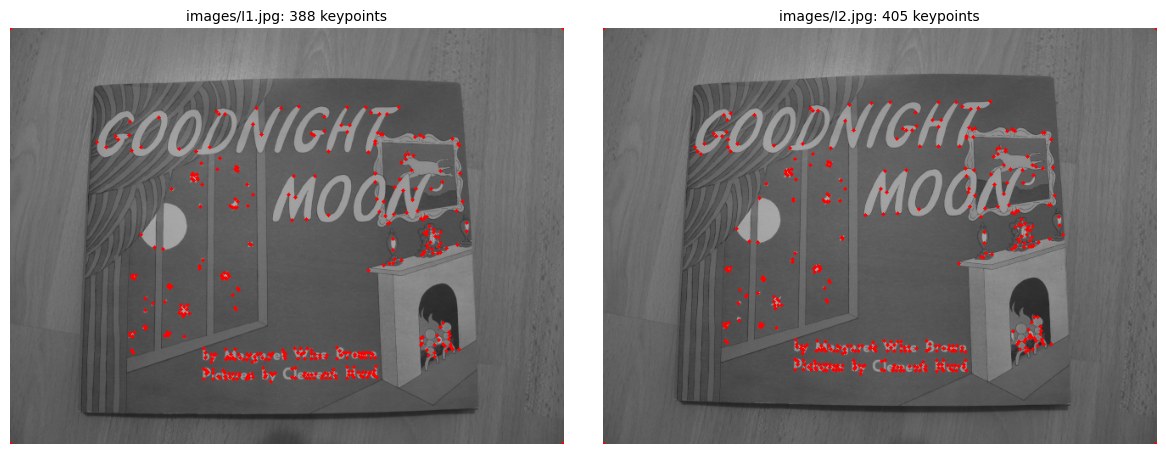

Descriptors: (384, 81) and (401, 81)


In [13]:
img1 = cv2.imread("images/I1.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("images/I2.jpg", cv2.IMREAD_GRAYSCALE)

# Harris corner detection
corners1, C1 = extract_harris(img1, HARRIS_SIGMA, HARRIS_K, HARRIS_THRESH)
corners2, C2 = extract_harris(img2, HARRIS_SIGMA, HARRIS_K, HARRIS_THRESH)
show_keypoints_pair(img1, corners1, img2, corners2, "images/I1.jpg", "images/I2.jpg")

# Extract descriptors
corners1 = filter_keypoints(img1, corners1, patch_size=9)
desc1 = extract_patches(img1, corners1, patch_size=9)
corners2 = filter_keypoints(img2, corners2, patch_size=9)
desc2 = extract_patches(img2, corners2, patch_size=9)
print(f"Descriptors: {desc1.shape} and {desc2.shape}")

### 2.2 SSD one-way nearest neighbors matching (15 pts)

The sum-of-squared-differences (SSD) is defined as:

$$\mathrm{SSD}(p, q) = \sum_i (p_i - q_i)^2.$$

Compute the SSD between the descriptors of all features from the first image and the second image.
**Avoid the for-loop by using vectorized computation in Python.**

Implement a one-way nearest neighbors matching protocol where each feature from the first image is
associated to its closest feature from the second image.

In [14]:
def ssd(desc1: np.ndarray, desc2: np.ndarray) -> np.ndarray:
    '''Compute the sum of squared differences (SSD) between two descriptor sets.

    Args:
        desc1 (np.ndarray): Descriptor set 1 of shape (q1, feature_dim).
        desc2 (np.ndarray): Descriptor set 2 of shape (q2, feature_dim).

    Returns:
        np.ndarray: SSD distances of shape (q1, q2).
    '''
    assert desc1.shape[1] == desc2.shape[1]
    # TODO: implement this function please
    
    distances = np.sum((desc1[:, np.newaxis, :] - desc2[np.newaxis, :, :]) ** 2, axis=2)

    return distances


def match_one_way(distances: np.ndarray) -> np.ndarray:
    '''Query the nearest neighbor in image 2 for each keypoint in image 1.

    Args:
        distances (np.ndarray): SSD distances of shape (q1, q2).

    Returns:
        np.ndarray: Array of shape (m, 2) storing the indices [index in image 1, index in image 2] of the matches.
    '''
    # TODO: implement the one-way nearest neighbor matching here
    # You may refer to np.argmin to find the index of the minimum over any axis

    matches = np.stack((np.arange(distances.shape[0]), np.argmin(distances, axis=1)), axis=1)

    return matches

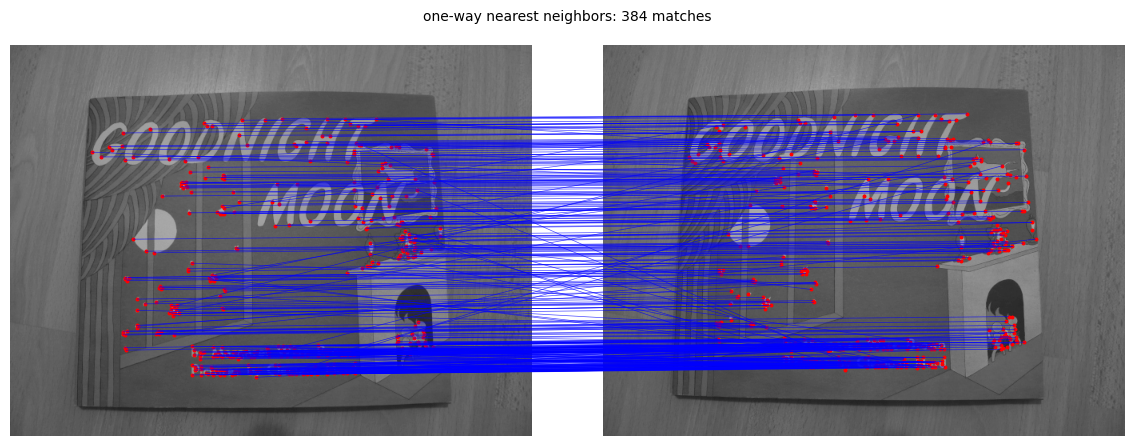

In [15]:
distances = ssd(desc1, desc2)
matches_ow = match_one_way(distances)
show_matches(img1, corners1, img2, corners2, matches_ow, "one-way nearest neighbors")

### 2.3 Mutual nearest neighbors / Ratio test (5 + 5 pts)

Implement the **mutual nearest neighbors** matching protocol where for each one-way match, you check
that it is also valid when swapping the images.

Implement the **ratio test** matching protocol where a one-way match is considered valid if the ratio
between the first and the second nearest neighbor is lower than a given threshold (for instance, you
can use 0.5). You may take advantage of the `np.partition` function.

In [16]:
def match_mutual(distances: np.ndarray) -> np.ndarray:
    '''Keep a one-way match only if it is also valid when swapping the images.

    Returns:
        np.ndarray: Array of shape (m, 2) storing the indices of the matches.
    '''
    # TODO: implement the mutual nearest neighbor matching here
    # You may refer to np.min to find the minimum over any axis
    
    way_one = match_one_way(distances)
    way_two = match_one_way(distances.T)
    
    mutual_matches_indices = np.where(way_two[way_one[:, 1], 1] == way_one[:, 0])[0]

    mutual_matches = way_one[mutual_matches_indices,:]

    return mutual_matches


def match_ratio(distances: np.ndarray, ratio_thresh: float = 0.5) -> np.ndarray:
    '''Keep a one-way match only if first / second nearest neighbor distance < ratio_thresh.

    Returns:
        np.ndarray: Array of shape (m, 2) storing the indices of the matches.
    '''
    # TODO: implement the ratio test matching here
    # You may use np.partition to find the k smallest values over a row

    first_nn_indices = np.argpartition(distances, 1, axis=1)[:, :2]
    first_nn_distances = distances[np.arange(distances.shape[0]), first_nn_indices[:, 0]]
    second_nn_distances = distances[np.arange(distances.shape[0]), first_nn_indices[:, 1]]

    ratio = first_nn_distances / second_nn_distances
    valid_matches_indices = np.where(ratio < ratio_thresh)[0]

    valid_matches = np.stack((valid_matches_indices, first_nn_indices[valid_matches_indices, 0]), axis=1)

    return valid_matches

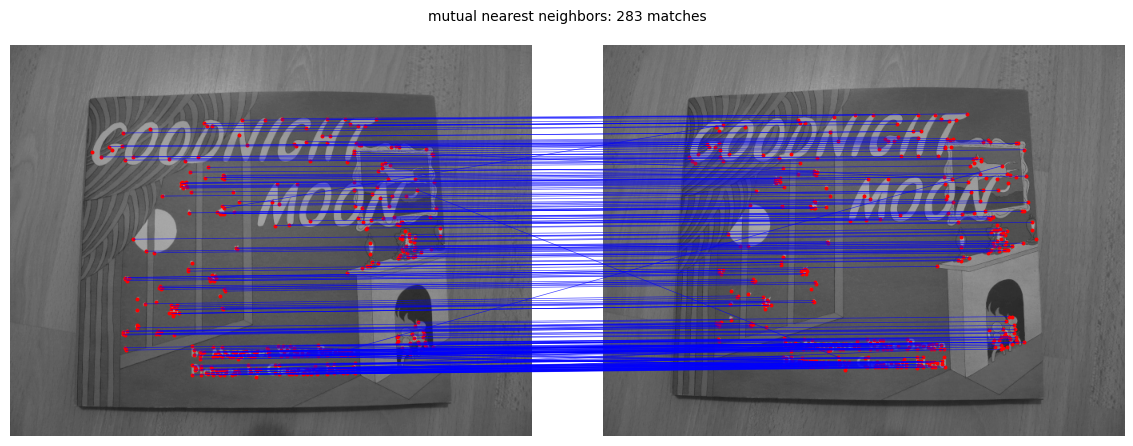

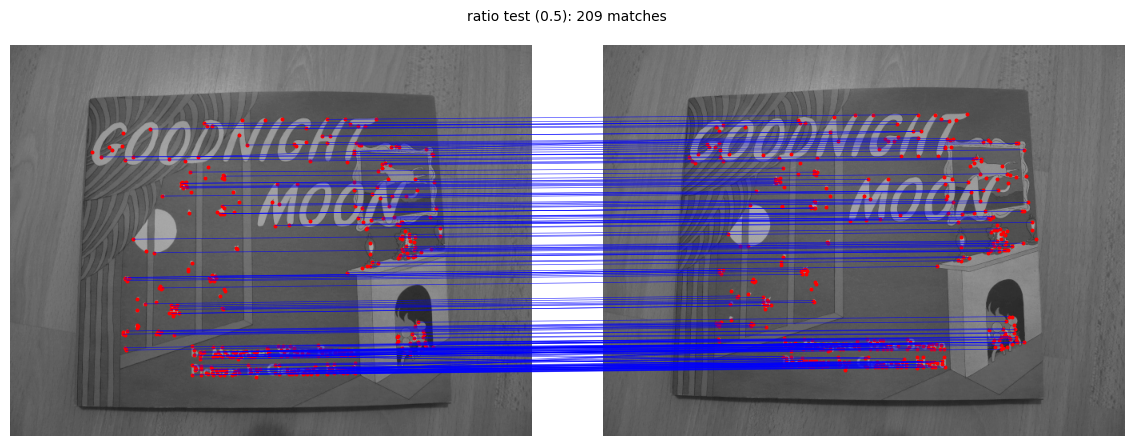

In [17]:
matches_mutual = match_mutual(distances)
show_matches(img1, corners1, img2, corners2, matches_mutual, "mutual nearest neighbors")

matches_ratio = match_ratio(distances, MATCHING_RATIO_TEST_THRESHOLD)
show_matches(img1, corners1, img2, corners2, matches_ratio, f"ratio test ({MATCHING_RATIO_TEST_THRESHOLD})")

### 2.4 What is patch matching invariant to? (interactive, 15 pts)

**Task.** As for the detector, we now change **image 2** in a controlled way, detect keypoints in both images with your detector, describe
them with the $9 \times 9$ patches and match them with **your** matchers. The two images show a planar scene, so a homography (provided in
`images/H_I1_to_I2.txt`) tells us where every keypoint of image 1 should land in image 2, and after the change also in the changed image 2.
A match is **correct** if the matched keypoint is within 3 pixels of that position: green lines are correct matches, red lines are wrong.
The *precision* is the share of correct matches.

The sliders are the same as before (`rotation`, `image resize`, `I + c`, `a · I`, now applied to image 2); `matcher` switches between your
three matching protocols.

In [18]:
%matplotlib widget
from helpers.match_invariance import MatchInvarianceExplorer

H_12 = np.loadtxt("images/H_I1_to_I2.txt")
matchers = {
    "one-way": match_one_way,
    "mutual": match_mutual,
    "ratio": lambda d: match_ratio(d, MATCHING_RATIO_TEST_THRESHOLD),
}
matching = MatchInvarianceExplorer(img1, img2, H_12, extract_harris, filter_keypoints, extract_patches, ssd, matchers,
                                   HARRIS_SIGMA, HARRIS_K, HARRIS_THRESH)
matching.interact()

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='rotation [°]', layout=Layou…

The summary runs seven fixed changes for the three matchers: the coloured part of a bar is the number of correct matches, the grey part
the number of matches in total; under each column you see how many keypoints your detector finds in the changed image 2 (401 without
change). Explain each column below (2–3 sentences each). Keep in mind what you found for the detector: which
part of the pipeline fails here, the detector or the descriptor?

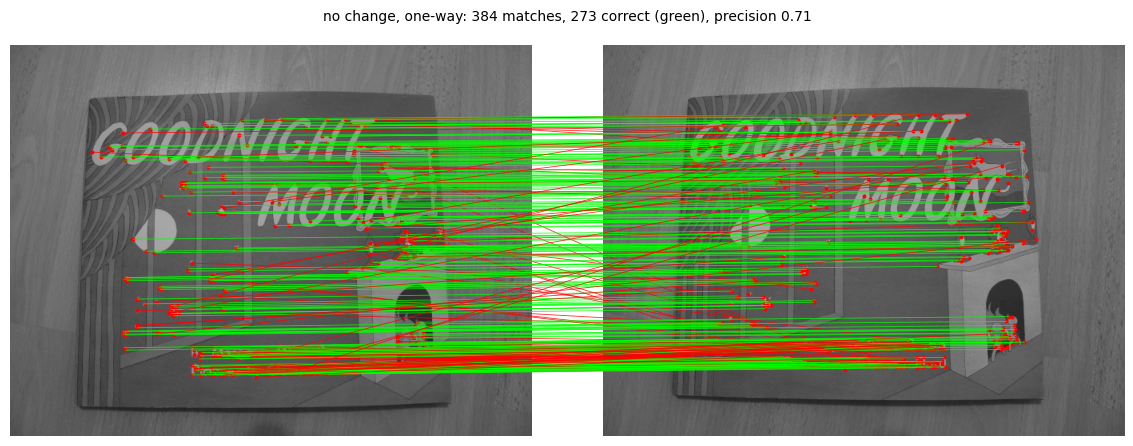

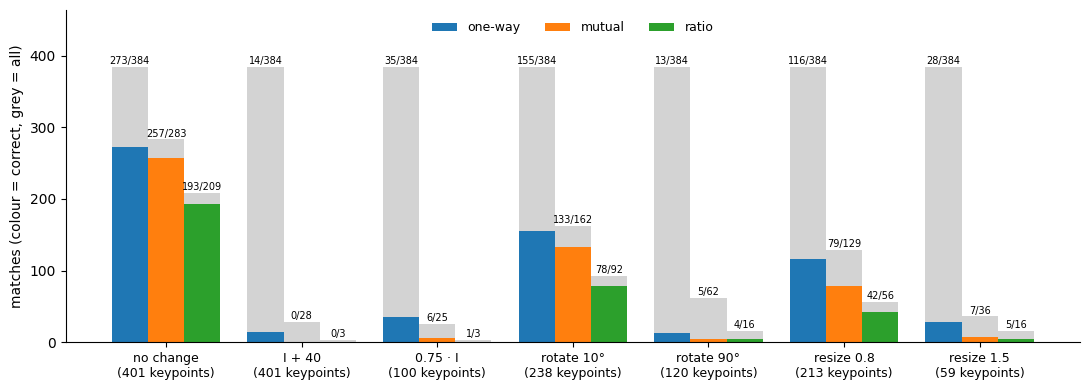

In [19]:
%matplotlib inline
matching.summary()

#### 2.4.1 no change (3 pts)

The images differ only by a small camera motion. Why are there wrong matches at all, and which matcher removes which kind of them?

✏️ There are wrong matches exactly because the images are displaced by a few pixels.
- The one-way matcher pairs up every keypoint with its closest keypoint in the displaced image, regardless of whether it is a good or bad match. Most of these matches fail because of two reasons: there are repeated structures (letters, corners, etc) throughout the image with similar matches or because the corresponding partner of some keypoints was not detected in the transformed image.
- The mutual matcher removes keypoints without a reciprocal corresponding keypoint in the transformed image.
- The ratio test removes ambiguous matches caused by repeated structures in the image. It prevents matches in which the second-best candidate is very similar to the best.

We observe the ratio test has the highest accuracy, followed by the mutual matcher, but they both discard a lot of correct matches.

#### 2.4.2 I + 40 (3 pts)

The detector finds the same keypoints (see the count under the column), yet almost no match is correct. Why? Propose a fix for the descriptor.

*Tip: expand $\mathrm{SSD}(\mathbf{p}, \mathbf{q} + c)$.*

✏️ Expanding $\mathrm{SSD}(\mathbf{p}, \mathbf{q} + c)$, we have

$$\mathrm{SSD}(\mathbf{p}, \mathbf{q} + c) = \mathrm{SSD}(\mathbf{p}, \mathbf{q}) - 2c \Sigma \left(p_i - q_i \right) + nc^2$$

This shows that for true matches, the first two terms are very small, but we have the remaining $nc^2$ left, which means true matches are no longer the closest.

To address this issue, we could consider normalizing the intensity across every patch by subtracting the patch average from every pixel before computing their SSD.


#### 2.4.3 0.75 · I (3 pts)

What is the impact, and why? Which stages of the pipeline are affected?

✏️ Both stages are affected. As discussed earlier, in the detector, scaling the pixel intensities by $a = 0.75$ will scale the Harris response by $a^4 \approx 0.32$, resulting in the loss of many keypoints. Then in the descriptor, the patch values are also scaled. For identical patches consider the following

$$\mathrm{SSD}(\mathbf{p}, a\mathbf{p}) = (1-a)^2 \sum_i p_i^2$$

This shows that identical matches will still have a residual, leading to wrong matches.

#### 2.4.4 rotate 10° and 90° (3 pts)

What is the impact, and why? Compare with the detector.

✏️ At 10° we have the following results
- One way: 155/384
- Mutual: 133/162
- Ratio: 78/92

At 90° we have the following results:
- One way: 13/384
- Mutual: 5/62
- Ratio: 4/16

We see that unlike the detector, our matcher performed very poorly on the 90 degree rotation. This occurs because when comparing the SSD between two patches, the pixels are ordered from top->bottom and left->right. This means that even if two patches represent the same structure, their numerical values end up at different positions in the patch, leading to a high SSD.

On the other hand, a 10° rotation means that any structure is only displaced by a few pixels on the transformed image, which implies that most patches around keypoints remain relatively unchanged.


#### 2.4.5 resize 0.8 and 1.5 (3 pts)

What is the impact, and why?

✏️ The descriptor suffers from the same issues as the detector under a scaling transformation.

For a scaling factor < 1, a lot of the features are compressed into smaller patches, losing out on detail and resolution, which might cutoff certain structures during our 9x9 patch gridization.

For a scaling factor > 1, structures in the image now occupy a much bigger grid. Therefore, comparing fixed 9x9 patches may fail to capture meaningful regions surrounding keypoints.

## References

[1] Chris Harris and Mike Stephens. "A combined corner and edge detector". In: *Proceedings of the
Alvey Vision Conference*. 1988.